<a href="https://colab.research.google.com/github/Veniveni123/CSA47-DEEP-LEARNING/blob/main/LAB%2011-20/Experiment%2014%3A%20Unfolded%20RNN%20Architecture%20Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Max Difference (Manual vs Keras): 1.0139165606409817e-07


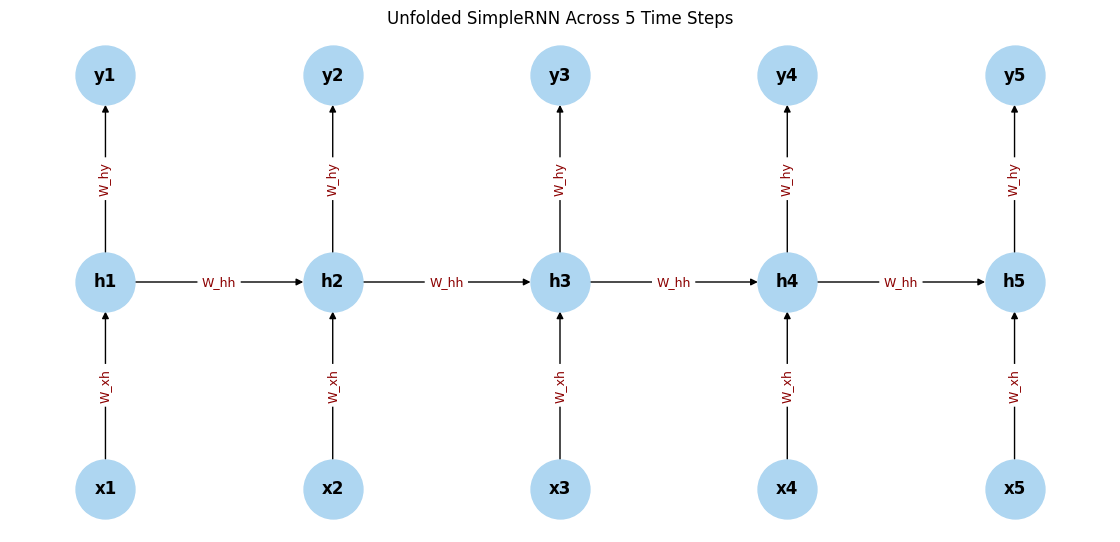

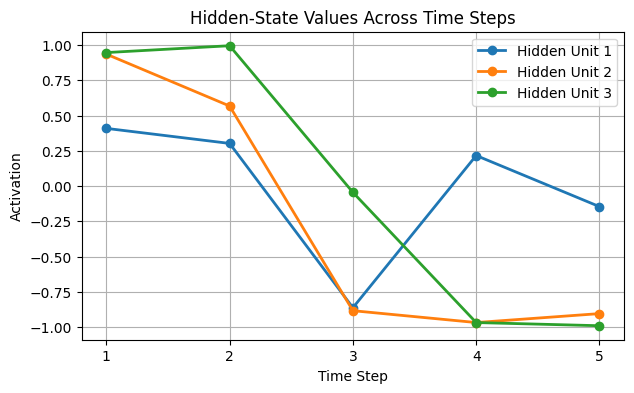

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import tensorflow as tf
from tensorflow import keras

np.random.seed(42)
tf.random.set_seed(42)

X_seq = np.random.randn(1, 5, 4).astype(np.float32)
inputs = keras.Input(shape=(5, 4))
rnn_out = keras.layers.SimpleRNN(3, return_sequences=True, name='rnn')(inputs)
outputs = keras.layers.Dense(2, name='out')(rnn_out)
model = keras.Model(inputs, outputs)

W_xh, W_hh, b_h = model.get_layer('rnn').get_weights()
W_hy, b_y = model.get_layer('out').get_weights()

h_t = np.zeros(3)
manual_h = []
for t in range(5):
    h_t = np.tanh(X_seq[0, t] @ W_xh + h_t @ W_hh + b_h)
    manual_h.append(h_t.copy())
manual_h = np.array(manual_h)
keras_h = model.get_layer('rnn')(X_seq).numpy()[0]

print("Max Difference (Manual vs Keras):", np.max(np.abs(manual_h - keras_h)))

G = nx.DiGraph()
pos = {}
for t in range(1, 6):
    G.add_node(f"x{t}"); pos[f"x{t}"] = (t * 2, 0)
    G.add_node(f"h{t}"); pos[f"h{t}"] = (t * 2, 1.5)
    G.add_node(f"y{t}"); pos[f"y{t}"] = (t * 2, 3)
    G.add_edge(f"x{t}", f"h{t}", label="W_xh")
    G.add_edge(f"h{t}", f"y{t}", label="W_hy")
    if t > 1:
        G.add_edge(f"h{t-1}", f"h{t}", label="W_hh")

plt.figure(figsize=(11, 5))
nx.draw(G, pos, with_labels=True, node_size=1800, node_color="#AED6F1", font_weight="bold", arrows=True)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, 'label'), font_color='darkred', font_size=9)
plt.title("Unfolded SimpleRNN Across 5 Time Steps")
plt.show()

plt.figure(figsize=(7, 4))
for u in range(3):
    plt.plot(range(1, 6), manual_h[:, u], 'o-', label=f'Hidden Unit {u+1}', linewidth=2)
plt.title("Hidden-State Values Across Time Steps")
plt.xlabel("Time Step")
plt.ylabel("Activation")
plt.xticks(range(1, 6))
plt.legend()
plt.grid(True)
plt.show()